In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3

import milopy.core as milo
import milopy.plot as milopl
import milopy.utils
from datetime import date

In [3]:
today = date.today()
date = today.strftime("%d_%m_%Y")

In [126]:
ipf_studies = ["Kaminski_2020", "Banovich_Kropski_2020", "Misharin_Budinger_2018", "Sheppard_2020"]
ipf_datasets = ipf_studies

In [204]:
# Show how many cells,datasets,studies are included in reference and query
ncells = denovo_recalc.obs.groupby("origin").size()
ndata = denovo_recalc.obs.groupby("origin").dataset.nunique()
nstudy = denovo_recalc.obs.groupby("origin").study.nunique()

names = ["cells", "datasets", "studies"]
counts_ipf = pd.concat([ncells,ndata,nstudy],axis=1)
counts_ipf = counts_ipf.rename({0:"cells"},axis=1)
counts_ipf

,cells,dataset,study
origin,,,
query,374495,4,4
reference,584884,14,11


In [122]:
# rename ipf query studies which are also included partly in healthy reference to differenciate between those
denovo_recalc.obs["study"] = denovo_recalc.obs["study"].astype("string")
denovo_recalc.obs.loc[(denovo_recalc.obs.origin == "query") & 
                      (denovo_recalc.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"study"] = denovo_recalc.obs.loc[(denovo_recalc.obs.origin == "query") & 
                      (denovo_recalc.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"dataset"].astype("string")
denovo_recalc.obs["study"] = denovo_recalc.obs["study"].astype("category")

denovo_ref.obs["study"] = denovo_ref.obs["study"].astype("string")
denovo_ref.obs.loc[(denovo_ref.obs.origin == "query") & 
                      (denovo_ref.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"study"] = denovo_ref.obs.loc[(denovo_ref.obs.origin == "query") & 
                      (denovo_ref.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"dataset"].astype("string")
denovo_ref.obs["study"] = denovo_ref.obs["study"].astype("category")

scarches_unlabeled.obs["study"] = scarches_unlabeled.obs["study"].astype("string")
scarches_unlabeled.obs.loc[(scarches_unlabeled.obs.origin == "query") & 
                      (scarches_unlabeled.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"study"] = scarches_unlabeled.obs.loc[(scarches_unlabeled.obs.origin == "query") & 
                      (scarches_unlabeled.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"dataset"].astype("string")
scarches_unlabeled.obs["study"] = scarches_unlabeled.obs["study"].astype("category")

scarches_labeled.obs["study"] = scarches_labeled.obs["study"].astype("string")
scarches_labeled.obs.loc[(scarches_labeled.obs.origin == "query") & 
                      (scarches_labeled.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"study"] = scarches_labeled.obs.loc[(scarches_labeled.obs.origin == "query") & 
                      (scarches_labeled.obs.study.isin(["Banovich_Kropski_2020", "Misharin_Budinger_2018"])),"dataset"].astype("string")
scarches_labeled.obs["study"] = scarches_labeled.obs["study"].astype("category")

In [70]:
with open('/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/colordict_datasets_studies.pkl', 'wb') as f:
    pickle.dump(colordict, f)

In [53]:
#Import color palette to get consistent colors across figures
import pickle  
with open('/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/colordict.pkl', 'rb') as f:
        colordict = pickle.load(f)

In [68]:
np.unique(denovo_recalc.obs.loc[denovo_recalc.obs.origin=="reference","study"])

array(['Banovich_Kropski_2020', 'Barbry_Leroy_2020', 'Jain_Misharin_2021',
       'Krasnow_2020', 'Lafyatis_Rojas_2019', 'Meyer_2019',
       'Misharin_2021', 'Misharin_Budinger_2018', 'Nawijn_2021',
       'Seibold_2020', 'Teichmann_Meyer_2019'], dtype=object)

In [69]:
# Add missing colors
colordict["Erythroblast"] = "#EA923C"
colordict["query"] = "#1f77b4"
colordict["reference"] = "#ff7f0e"
colordict["Disease"] = '#37485c'
colordict["Healthy"] = '#c25a8d'
colordict["cells"] = '#37485c'
colordict["nuclei"] = '#c25a8d'
colordict["Kaminski_2020"] = '#1c3144'
colordict["Banovich_Kropski_2020"] = '#596f62'
colordict["Misharin_Budinger_2018"] = '#a4778b'
colordict["Banovich_Kropski_2020_disease"] = '#596f62'
colordict["Misharin_Budinger_2018_disease"] = '#a4778b'
colordict["Sheppard_2020"] = '#c3d898'
colordict["Meyer_2021"] = "#1c3144"
colordict["Meyer_2021_3prime"] = "#1c3144"
colordict["Meyer_2021_5prime"] = "#596f62"
colordict["Duong_lungMAP_unpubl"] = "#1c3144"
colordict["Eils_2020"] = "#596f62"
colordict["Sun_2020"] = "#a4778b"
colordict["Duong_lungMAP_unpubl"] = "#1c3144"
colordict["Eils_2020"] = "#596f62"
colordict["Sun_2020_batch1"] = "#a4778b"
colordict["Sun_2020_batch2"] = "#c3d898"
colordict["Sun_2020_batch3"] = "#70161e"
colordict["Sun_2020_batch4"] = "#3c91e6"
colordict['Banovich_Kropski_2020'] = "#CCCCCC"
colordict['Barbry_Leroy_2020'] = "#CCCCCC"
colordict['Jain_Misharin_2021_10Xv1'] = "#CCCCCC"
colordict['Jain_Misharin_2021_10Xv2'] = "#CCCCCC"
colordict['Krasnow_2020'] = "#CCCCCC"
colordict['Lafyatis_Rojas_2019_10Xv1'] = "#CCCCCC"
colordict['Lafyatis_Rojas_2019_10Xv2'] = "#CCCCCC"
colordict['Meyer_2019'] = "#CCCCCC"
colordict['Misharin_2021'] = "#CCCCCC"
colordict['Misharin_Budinger_2018'] = "#CCCCCC"
colordict['Nawijn_2021'] = "#CCCCCC"
colordict['Seibold_2020_10Xv2'] = "#CCCCCC"
colordict['Seibold_2020_10Xv3'] = "#CCCCCC"
colordict['Teichmann_Meyer_2019'] = "#CCCCCC"

colordict['Banovich_Kropski_2020'] = "#CCCCCC"
colordict['Barbry_Leroy_2020'] = "#CCCCCC"
colordict['Jain_Misharin_2021'] = "#CCCCCC"
colordict['Krasnow_2020'] = "#CCCCCC"
colordict['Lafyatis_Rojas_2019'] = "#CCCCCC"
colordict['Meyer_2019'] = "#CCCCCC"
colordict['Misharin_2021'] = "#CCCCCC"
colordict['Misharin_Budinger_2018'] = "#CCCCCC"
colordict['Nawijn_2021'] = "#CCCCCC"
colordict['Seibold_2020'] = "#CCCCCC"
colordict['Teichmann_Meyer_2019'] = "#CCCCCC"

In [6]:
# Import datasets with Milos differential abundance values
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_denovo_recalc_milo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_denovo_ref_milo.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_scarches_unlabeled_milo.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_scarches_labeled_milo.h5ad")

In [7]:
# get original scanvi_labels for scarches_unlabeld back
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("string")
scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label_original"] = scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label"].astype(str)
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("category")

In [8]:
# Check which conditions are set to be "Healthy"
np.unique(denovo_recalc.obs.condition)

array(['Control', 'Healthy', 'IPF', 'carcinoid',
       'had TB as a child (fully treated over 30+ years)', 'healthy',
       'nan', 'non-small cell lung cancer',
       'worsening respiratory function prior to arrest'], dtype=object)

In [9]:
# Classify conditions in "Healthy" and "Disease"
scarches_unlabeled.obs["condition_cat"] = ["Healthy" if cond in ["Control", "Healthy", "healthy", "nan"] else "Disease" for cond in scarches_unlabeled.obs["condition"]]
denovo_recalc.obs["condition_cat"] = ["Healthy" if cond in ["Control", "Healthy", "healthy", "nan"] else "Disease" for cond in scarches_unlabeled.obs["condition"]]

In [10]:
# Calculate all different combinations of logFC values we want to compare
scarches_unlabeled.obs["diff_denovo_recalc"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_unlabeled.obs["diff_denovo_ref"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_unlabeled.obs["diff_scArches_labeled"] = abs(scarches_unlabeled.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_recalc"] = abs(scarches_labeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_ref"] = abs(scarches_labeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_labeled.obs["diff_scArches_unlabeled"] = abs(scarches_labeled.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_ref.obs["diff_denovo_recalc"] = abs(denovo_ref.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
denovo_ref.obs["diff_scArches_labeled"] = abs(denovo_ref.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_ref.obs["diff_scArches_unlabeled"] = abs(denovo_ref.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_unlabeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_labeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_recalc.obs["diff_denovo_ref"] = abs(denovo_recalc.obs.logFC_avg - denovo_ref.obs.logFC_avg)

In [11]:
# Delete any left color assignments
del scarches_unlabeled.uns['scanvi_label_colors']
del scarches_labeled.uns['scanvi_label_colors']
del denovo_recalc.uns['scanvi_label_colors']
del denovo_ref.uns['scanvi_label_colors']

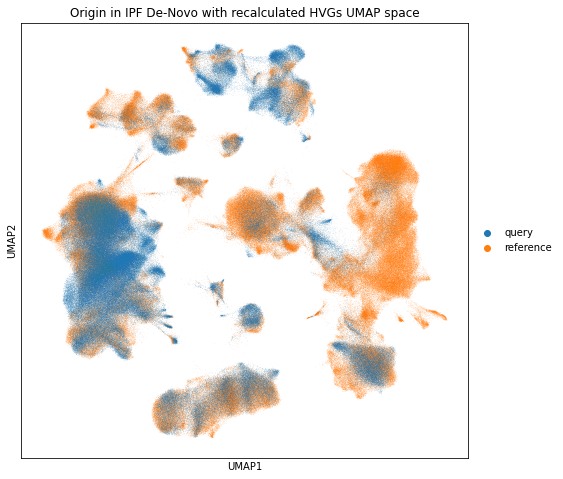

In [18]:
sc.pl.umap(denovo_recalc, color="origin", palette = colordict, size = 0.3,
          title = "Origin in IPF De-Novo with recalculated HVGs UMAP space",
          save = f"_ipf_denovo_recalc_origin_{date}.png")

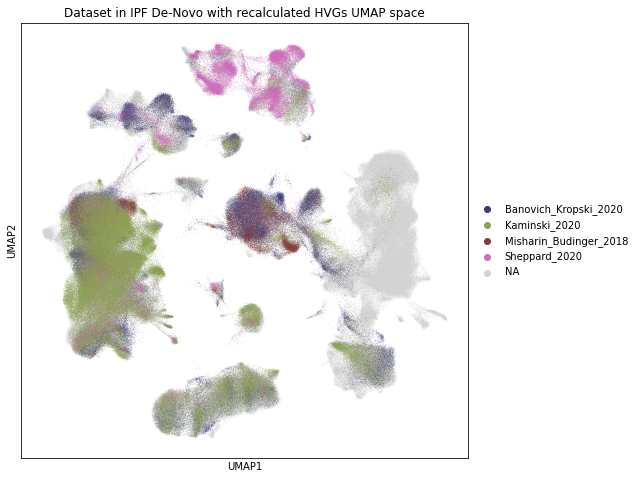

In [127]:
sc.pl.umap(denovo_recalc, color="dataset",  size = 0.5, groups = ipf_datasets, palette = "tab20b",
          title = "Dataset in IPF De-Novo with recalculated HVGs UMAP space")

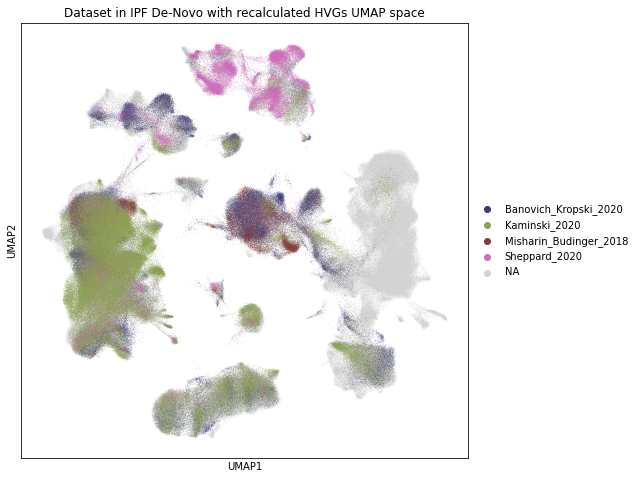

In [128]:
sc.pl.umap(denovo_recalc, color="study",  size = 0.5, groups = ipf_studies, palette = "tab20b",
          title = "Dataset in IPF De-Novo with recalculated HVGs UMAP space")

In [45]:
denovo_recalc.obs.loc[:,["dataset","study","origin"]].drop_duplicates()

,dataset,study,origin
GCGACCATCCCTAACC_SC22-0,Misharin_Budinger_2018,Misharin_Budinger_2018,reference
P2_1_GCGCAACCAGTTAACC-0,Krasnow_2020,Krasnow_2020,reference
CTTGATTGTCAGTTTG_T164-0,Seibold_2020_10Xv3,Seibold_2020,reference
GTCACGGAGACGCAAC_F02617-0,Banovich_Kropski_2020,Banovich_Kropski_2020,reference
CAGCCACAGTCACTA_GRO-03_biopsy-0,Nawijn_2021,Nawijn_2021,reference
TCATGAGGTCGCAGTC_SC142-0,Misharin_2021,Misharin_2021,reference
TAAGTGCCACTGTTAG_T121-0,Seibold_2020_10Xv2,Seibold_2020,reference
D363_Brus_Dis1_ATAAGAGAGCACCGTC-1-26-0,Barbry_Leroy_2020,Barbry_Leroy_2020,reference
7185212_CTGGTCTCACTGTTAG-0,Teichmann_Meyer_2019,Teichmann_Meyer_2019,reference
ACCCACTGAACTGC-SC14-0,Lafyatis_Rojas_2019_10Xv1,Lafyatis_Rojas_2019,reference


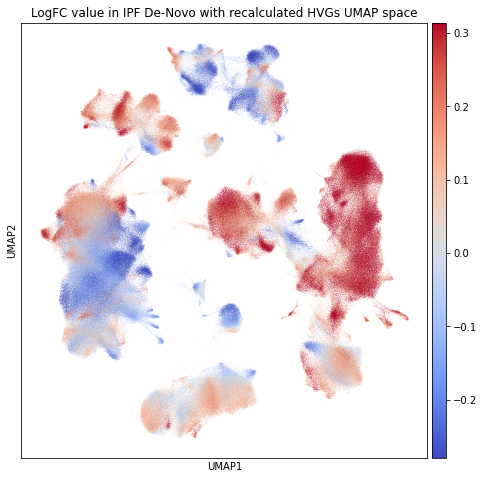

In [17]:
sc.pl.umap(denovo_recalc, color = "logFC_avg", color_map = "coolwarm", vmin = "p10", vmax = "p90", size = 0.3,
          title = "LogFC value in IPF De-Novo with recalculated HVGs UMAP space",
          save = f"_ipf_denovo_recalc_logFC_{date}.png")

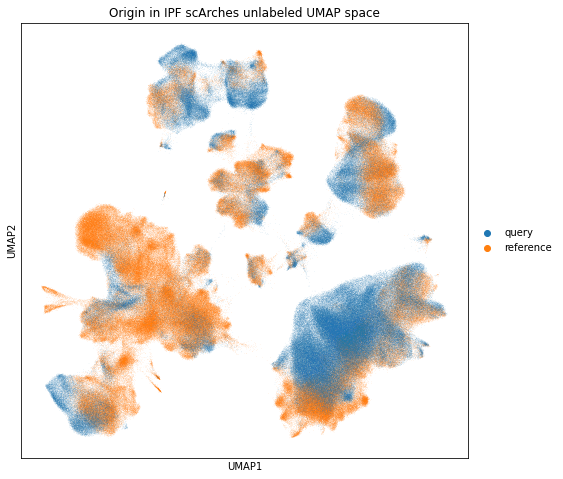

In [19]:
sc.pl.umap(scarches_unlabeled, color="origin", palette = colordict, size = 0.3,
          title = "Origin in IPF scArches unlabeled UMAP space",
          save = f"_ipf_scarches_unlabeled_origin_{date}.png")

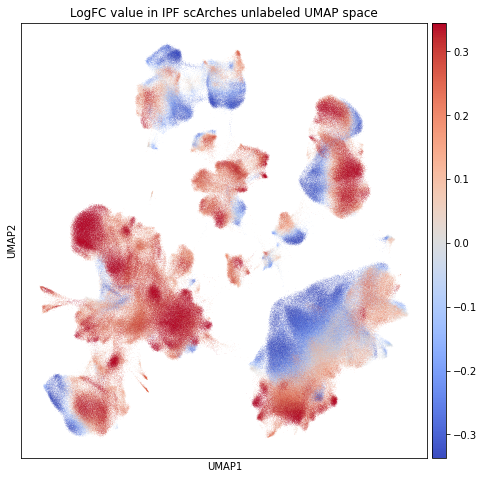

In [20]:
sc.pl.umap(scarches_unlabeled, color="logFC_avg", color_map = "coolwarm", vmin = "p10", vmax = "p90", size = 0.3,
          title = "LogFC value in IPF scArches unlabeled UMAP space",
          save = f"_ipf_scarches_unlabeled_logFC_{date}.png")

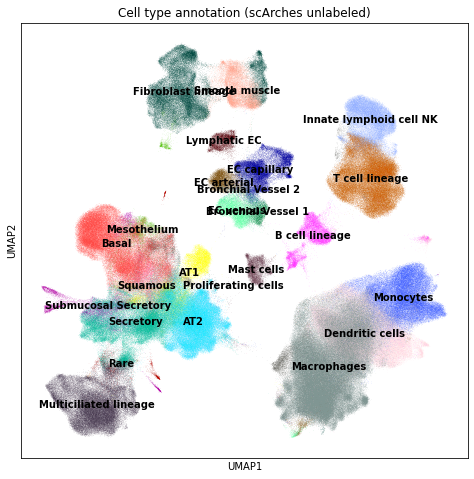

In [21]:
sc.pl.umap(scarches_unlabeled, color = "C_scArches", palette = colordict, legend_loc = "on data", size = 0.3,
          title = "Cell type annotation (scArches unlabeled)",
          save = f"_ipf_scarches_unlabeled_annotation_{date}.png")

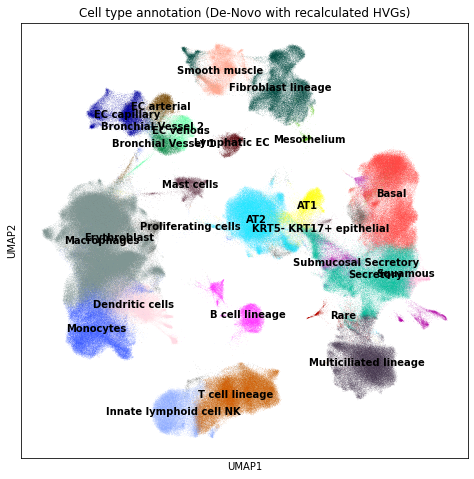

In [22]:
sc.pl.umap(denovo_recalc, color = "C_scANVI", palette = colordict, legend_loc = "on data", size = 0.3,
          title = "Cell type annotation (De-Novo with recalculated HVGs)",
          save = f"_ipf_denovo_recalc_annotation_{date}.png")

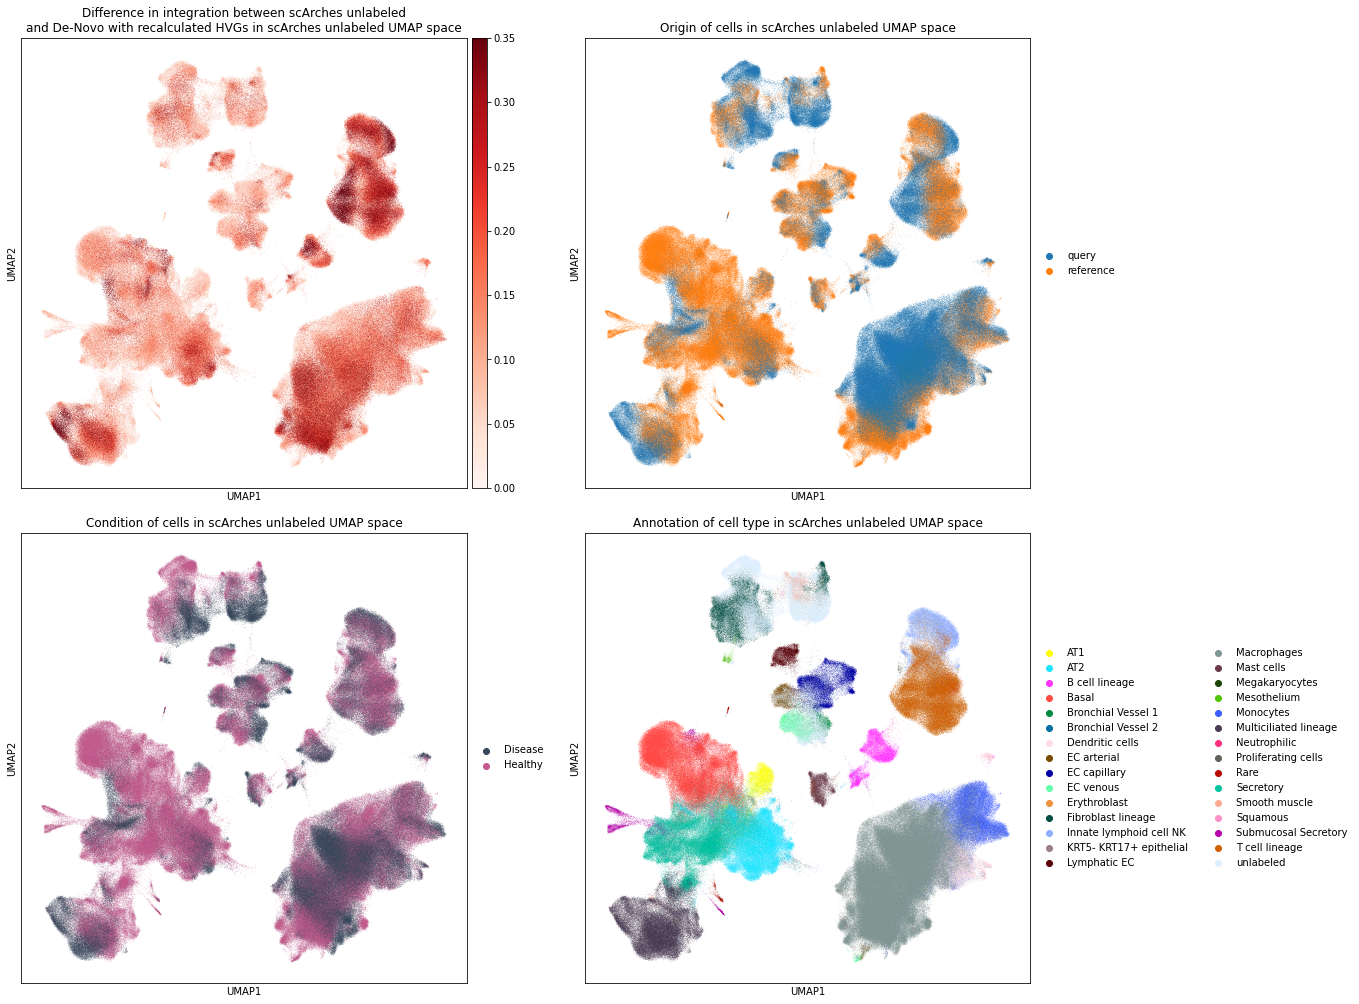

In [24]:
sc.pl.umap(scarches_unlabeled, color = ["diff_denovo_recalc", "origin", "condition_cat", "scanvi_label_original"], 
          vmin = 0, vmax = 0.35, cmap = "Reds", palette = colordict, size = 0.5, wspace=0.15, hspace = 0.1, ncols = 2,
          save = f"_ipf_scarches_unlabeled_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in scArches unlabeled UMAP space",
                  "Origin of cells in scArches unlabeled UMAP space",
                  "Condition of cells in scArches unlabeled UMAP space",
                  "Annotation of cell type in scArches unlabeled UMAP space"])

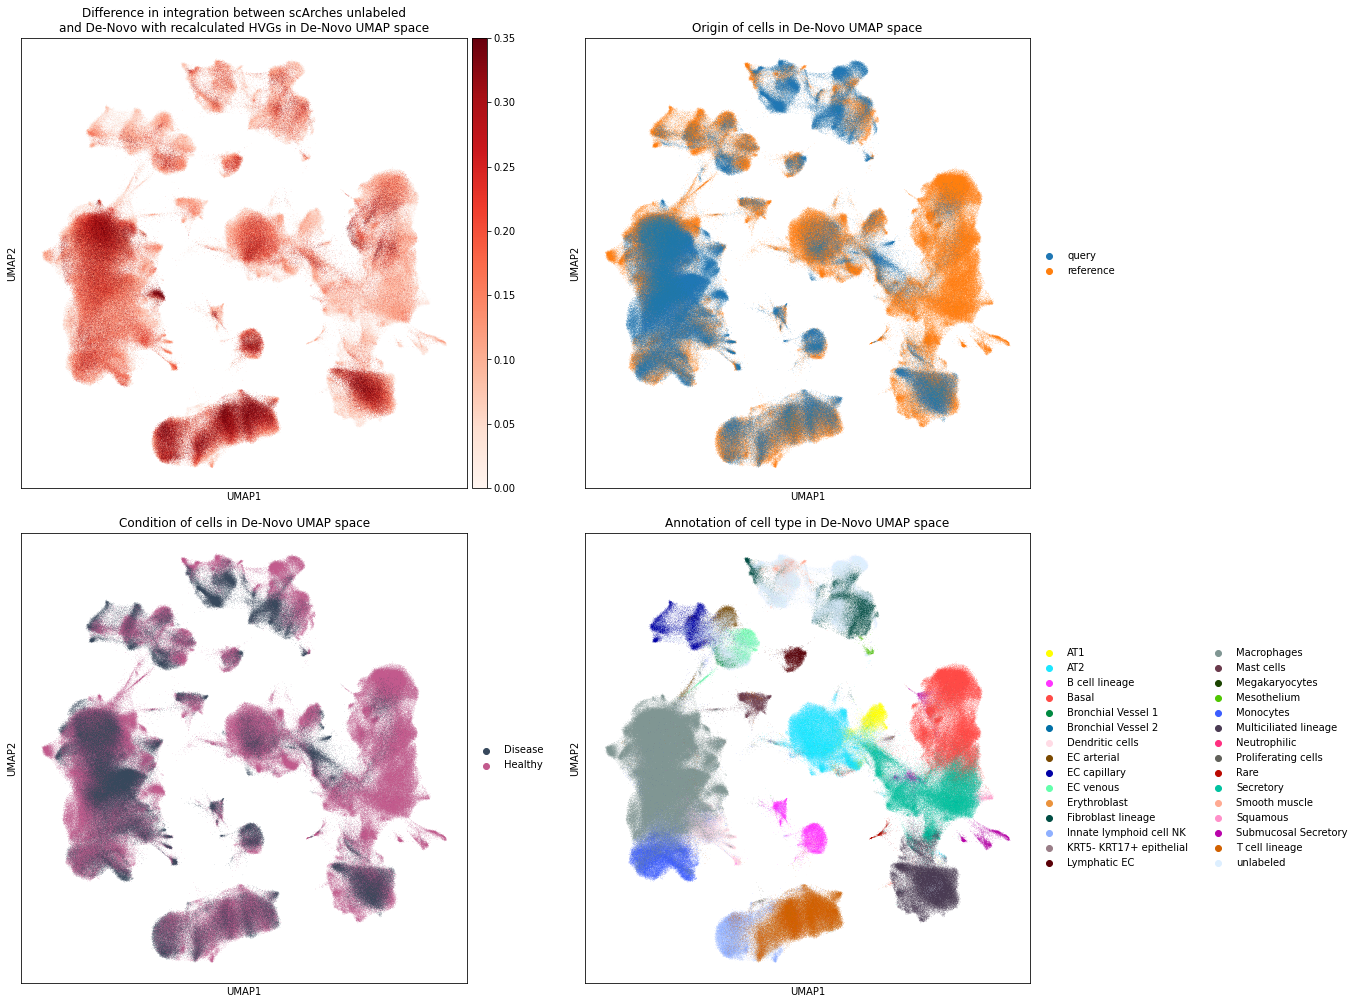

In [25]:
sc.pl.umap(denovo_recalc, color = ["diff_scArches_unlabeled", "origin", "condition_cat", "scanvi_label"], 
          vmin = 0, vmax = 0.35, cmap = "Reds", palette = colordict, size = 0.5, wspace=0.15, hspace = 0.1, ncols = 2,
          save= f"_ipf_denovo_recalc_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in De-Novo UMAP space",
                  "Origin of cells in De-Novo UMAP space",
                  "Condition of cells in De-Novo UMAP space",
                  "Annotation of cell type in De-Novo UMAP space"])

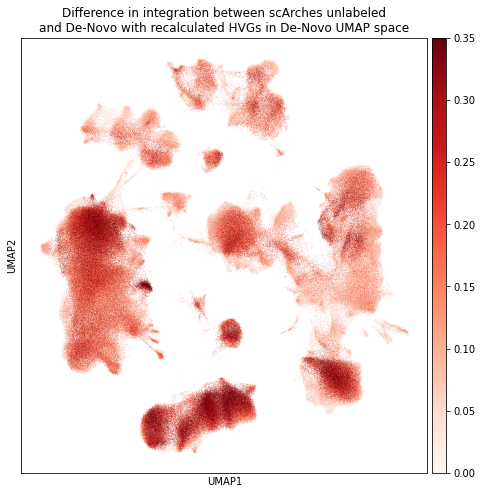

In [33]:
sc.pl.umap(denovo_recalc, color = ["diff_scArches_unlabeled"], 
          vmin = 0, vmax = 0.35, cmap = "Reds", palette = colordict, size = 0.5, wspace=0.15, hspace = 0.1,
          save= f"_ipf_denovo_recalc_absolute_diff_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in De-Novo UMAP space"])

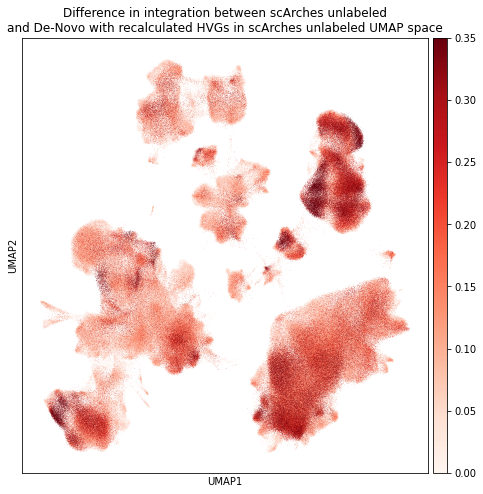

In [35]:
sc.pl.umap(scarches_unlabeled, color = ["diff_denovo_recalc"], 
          vmin = 0, vmax = 0.35, cmap = "Reds", palette = colordict, size = 0.5, wspace=0.15, hspace = 0.1,
          save = f"_ipf_scarches_unlabeled_absolute_diff{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in scArches unlabeled UMAP space"])

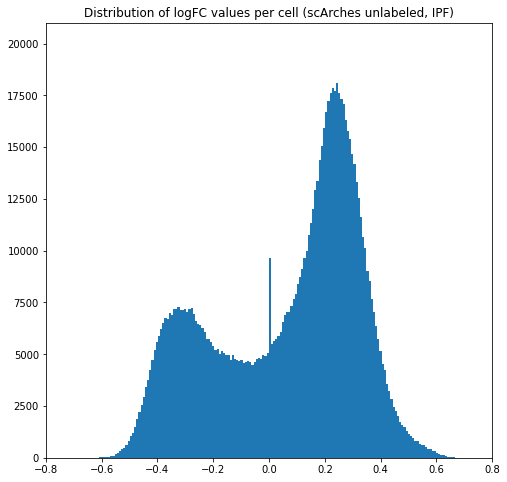

In [27]:
plt.hist(scarches_unlabeled.obs.logFC_avg, bins=200)
plt.ylim(0,21000)
plt.xlim(-0.8,0.8)
plt.title("Distribution of logFC values per cell (scArches unlabeled, IPF)")
plt.savefig(f"figures/ipf_scarches_unlabeled_distr_logFC_{date}.png")

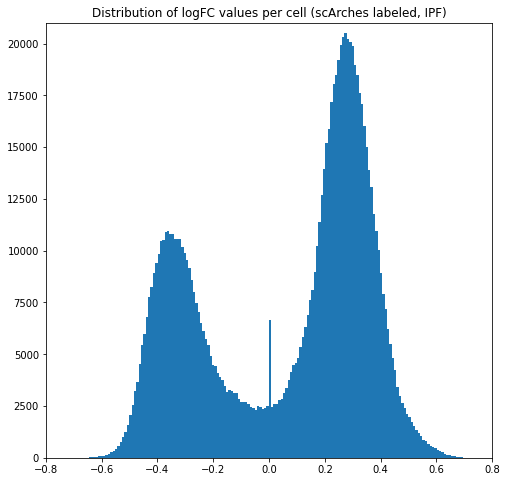

In [28]:
plt.hist(scarches_labeled.obs.logFC_avg, bins=200)
plt.ylim(0,21000)
plt.xlim(-0.8,0.8)
plt.title("Distribution of logFC values per cell (scArches labeled, IPF)")
plt.savefig(f"figures/ipf_scarches_labeled_distr_logFC_{date}.png")

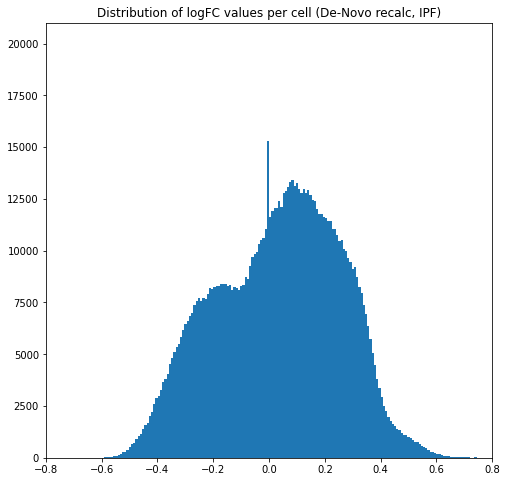

In [29]:
plt.hist(denovo_recalc.obs.logFC_avg, bins=200)
plt.ylim(0,21000)
plt.xlim(-0.8,0.8)
plt.title("Distribution of logFC values per cell (De-Novo recalc, IPF)")
plt.savefig(f"figures/ipf_denovo_recalc_distr_logFC_{date}.png")

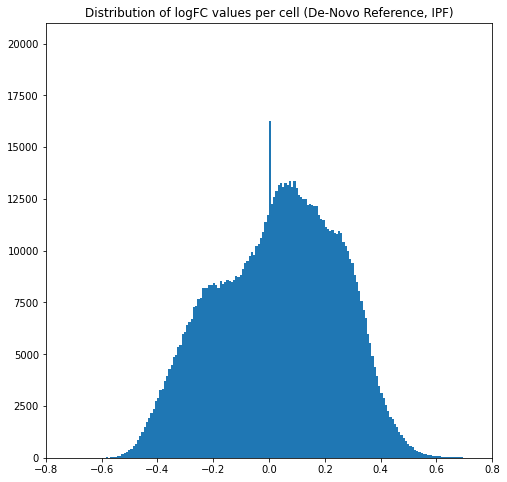

In [30]:
plt.hist(denovo_ref.obs.logFC_avg, bins=200)
plt.ylim(0,21000)
plt.xlim(-0.8,0.8)
plt.title("Distribution of logFC values per cell (De-Novo Reference, IPF)")
plt.savefig(f"figures/ipf_denovo_ref_distr_logFC_{date}.png")

# Violin Plots 

In [63]:
# Sort labels by median of difference of logFC value
labels_sorted = list(scarches_unlabeled.obs.groupby("scanvi_label_original")["diff_denovo_recalc"].median().sort_values().index)

In [64]:
sort_by = [labels_sorted.index(x) for x in sorted(labels_sorted)]

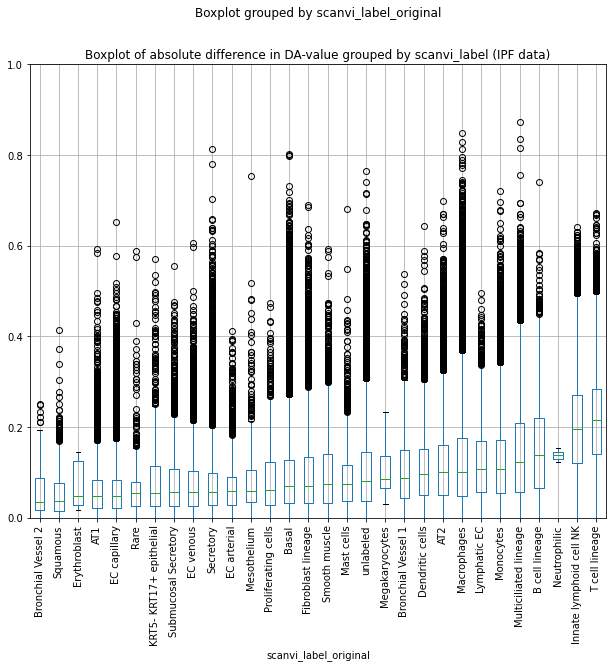

In [65]:
scarches_unlabeled.obs.boxplot(column='diff_denovo_recalc',by='scanvi_label_original', positions=sort_by )
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by scanvi_label (IPF data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/ipf_boxplot_scanvi_label_{date}.jpg")

In [66]:
cell_labels_lvl3 = ["Erythroblast", "KRT5- KRT17+ epithelial"]
cell_labels_lvl4 = ["Fibroblasts PLIN2+", "Ionocyte", "Neuroendocrine", "Langerin+ DC", "Regulatory T cells", "T cells proliferating"]

cells_lvl3 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_3"].isin(cell_labels_lvl3)]
cells_lvl3.obs["diff_denovo_recalc_abs"] = abs(cells_lvl3.obs.diff_denovo_recalc)

cells_lvl4 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_4"].isin(cell_labels_lvl4)]
cells_lvl4.obs["diff_denovo_recalc_abs"] = abs(cells_lvl4.obs.diff_denovo_recalc)

Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.


In [67]:
labels_sorted_lvl3 = list(cells_lvl3.obs.groupby("ann_level_3")["diff_denovo_recalc_abs"].median().sort_values().index)
labels_sorted_lvl4 = list(cells_lvl4.obs.groupby("ann_level_4")["diff_denovo_recalc_abs"].median().sort_values().index)

In [68]:
sort_by_lvl3 = [labels_sorted_lvl3.index(x) for x in sorted(labels_sorted_lvl3)]
sort_by_lvl4 = [labels_sorted_lvl4.index(x) for x in sorted(labels_sorted_lvl4)]

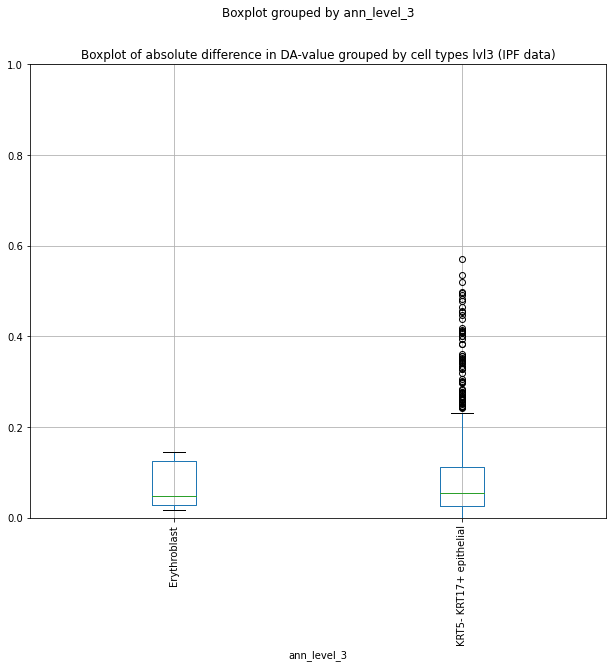

In [70]:
cells_lvl3.obs.boxplot(column='diff_denovo_recalc',by='ann_level_3', positions=sort_by_lvl3)
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by cell types lvl3 (IPF data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/ipf_boxplot_new_lvl3_{date}.jpg")

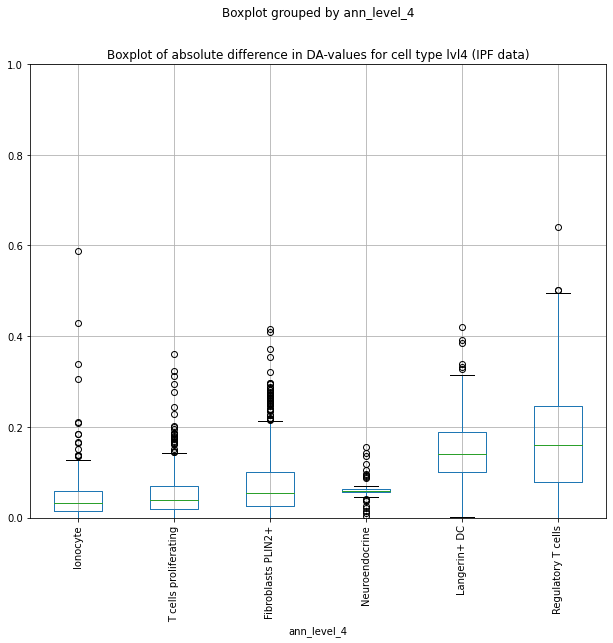

In [72]:
cells_lvl4.obs.boxplot(column='diff_denovo_recalc',by='ann_level_4', positions=sort_by_lvl4)
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-values for cell type lvl4 (IPF data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig(f"figures/ipf_boxplot_lvl4_{date}.jpg")

# Clustering analysis

In [47]:
sc.tl.leiden(denovo_recalc, resolution= 0.1)

running Leiden clustering
    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:17:09)


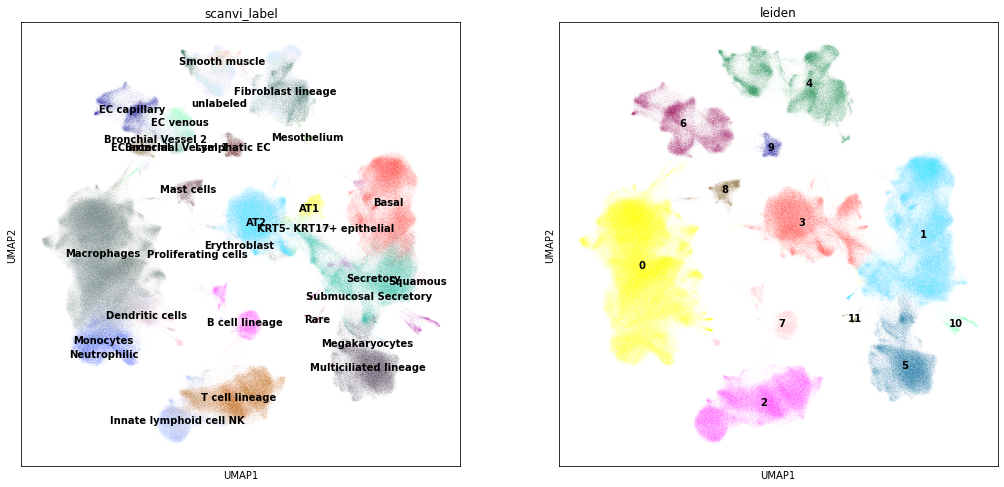

In [48]:
sc.pl.umap(denovo_recalc, color=["scanvi_label","leiden"], legend_loc="on data")

In [49]:
subset_immune = denovo_recalc[(denovo_recalc.obs.leiden == "0") | (denovo_recalc.obs.leiden == "2")].copy()

/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


In [50]:
sc.pp.neighbors(subset_immune, n_neighbors=50, n_pcs=30, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:07:39)


In [51]:
sc.tl.umap(subset_immune)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:14:54)


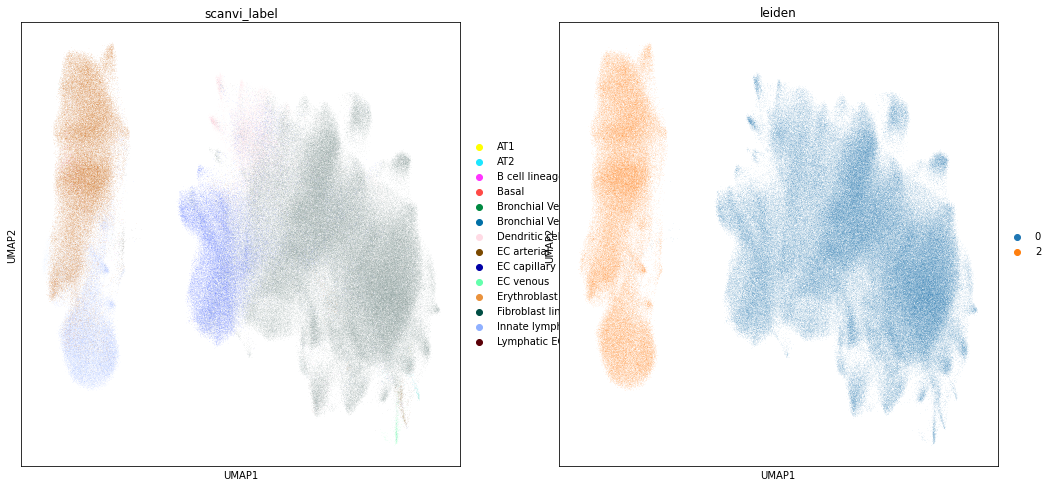

In [52]:
sc.pl.umap(subset_immune, color=["scanvi_label","leiden"])

In [53]:
sc.tl.leiden(subset_immune, resolution= 0.5,key_added = "leiden_sub")

running Leiden clustering
    finished: found 14 clusters and added
    'leiden_sub', the cluster labels (adata.obs, categorical) (0:16:03)


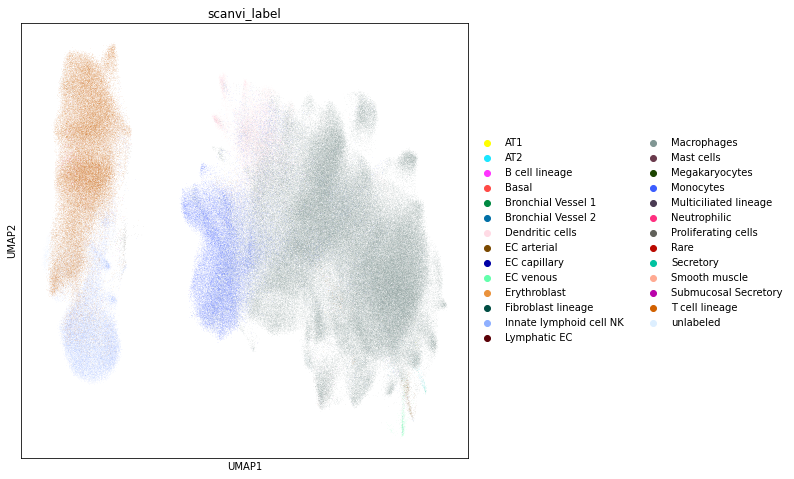

In [54]:
sc.pl.umap(subset_immune, color=["scanvi_label"])

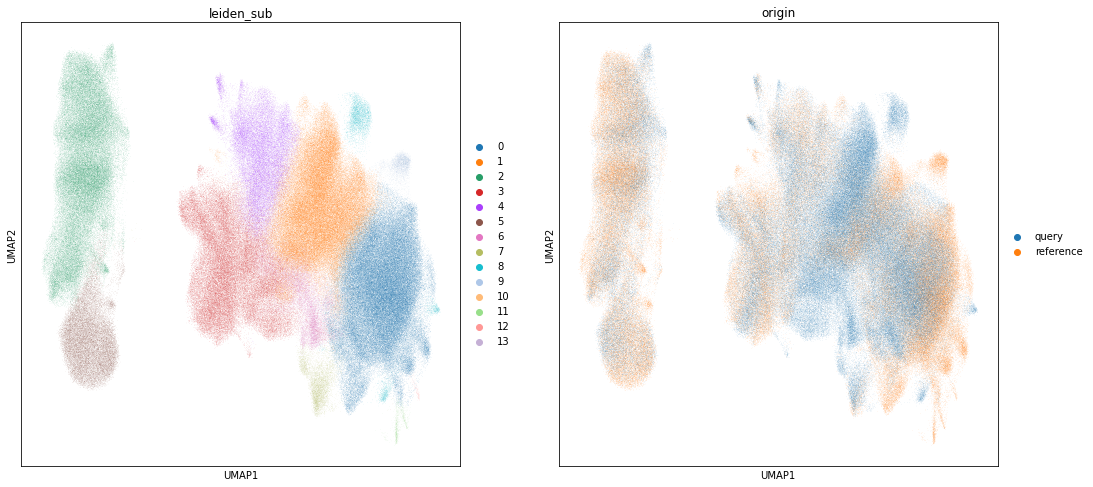

In [55]:
sc.pl.umap(subset_immune, color=["leiden_sub", "origin"])

In [124]:
subset_immune.raw.var.index = subset_immune.raw.var["gene_symbols-0"]

In [125]:
subset_immune.raw.var_names

CategoricalIndex(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR', 'CFH',
                  'FUCA2', 'GCLC', 'NFYA',
                  ...
                  nan, nan, nan, nan, nan, nan, nan, nan, nan, nan],
                 categories=['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1', 'A2ML1', 'A2ML1-AS1', 'A2ML1-AS2', ...], ordered=False, name='gene_symbols-0', dtype='category', length=48717)

In [126]:
subset_immune.raw.var.index

CategoricalIndex(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR', 'CFH',
                  'FUCA2', 'GCLC', 'NFYA',
                  ...
                  nan, nan, nan, nan, nan, nan, nan, nan, nan, nan],
                 categories=['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1', 'A2ML1', 'A2ML1-AS1', 'A2ML1-AS2', ...], ordered=False, name='gene_symbols-0', dtype='category', length=48717)

ranking genes
    finished: added to `.uns['t-test']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:01:38)


IndexError: index 25 is out of bounds for axis 0 with size 25

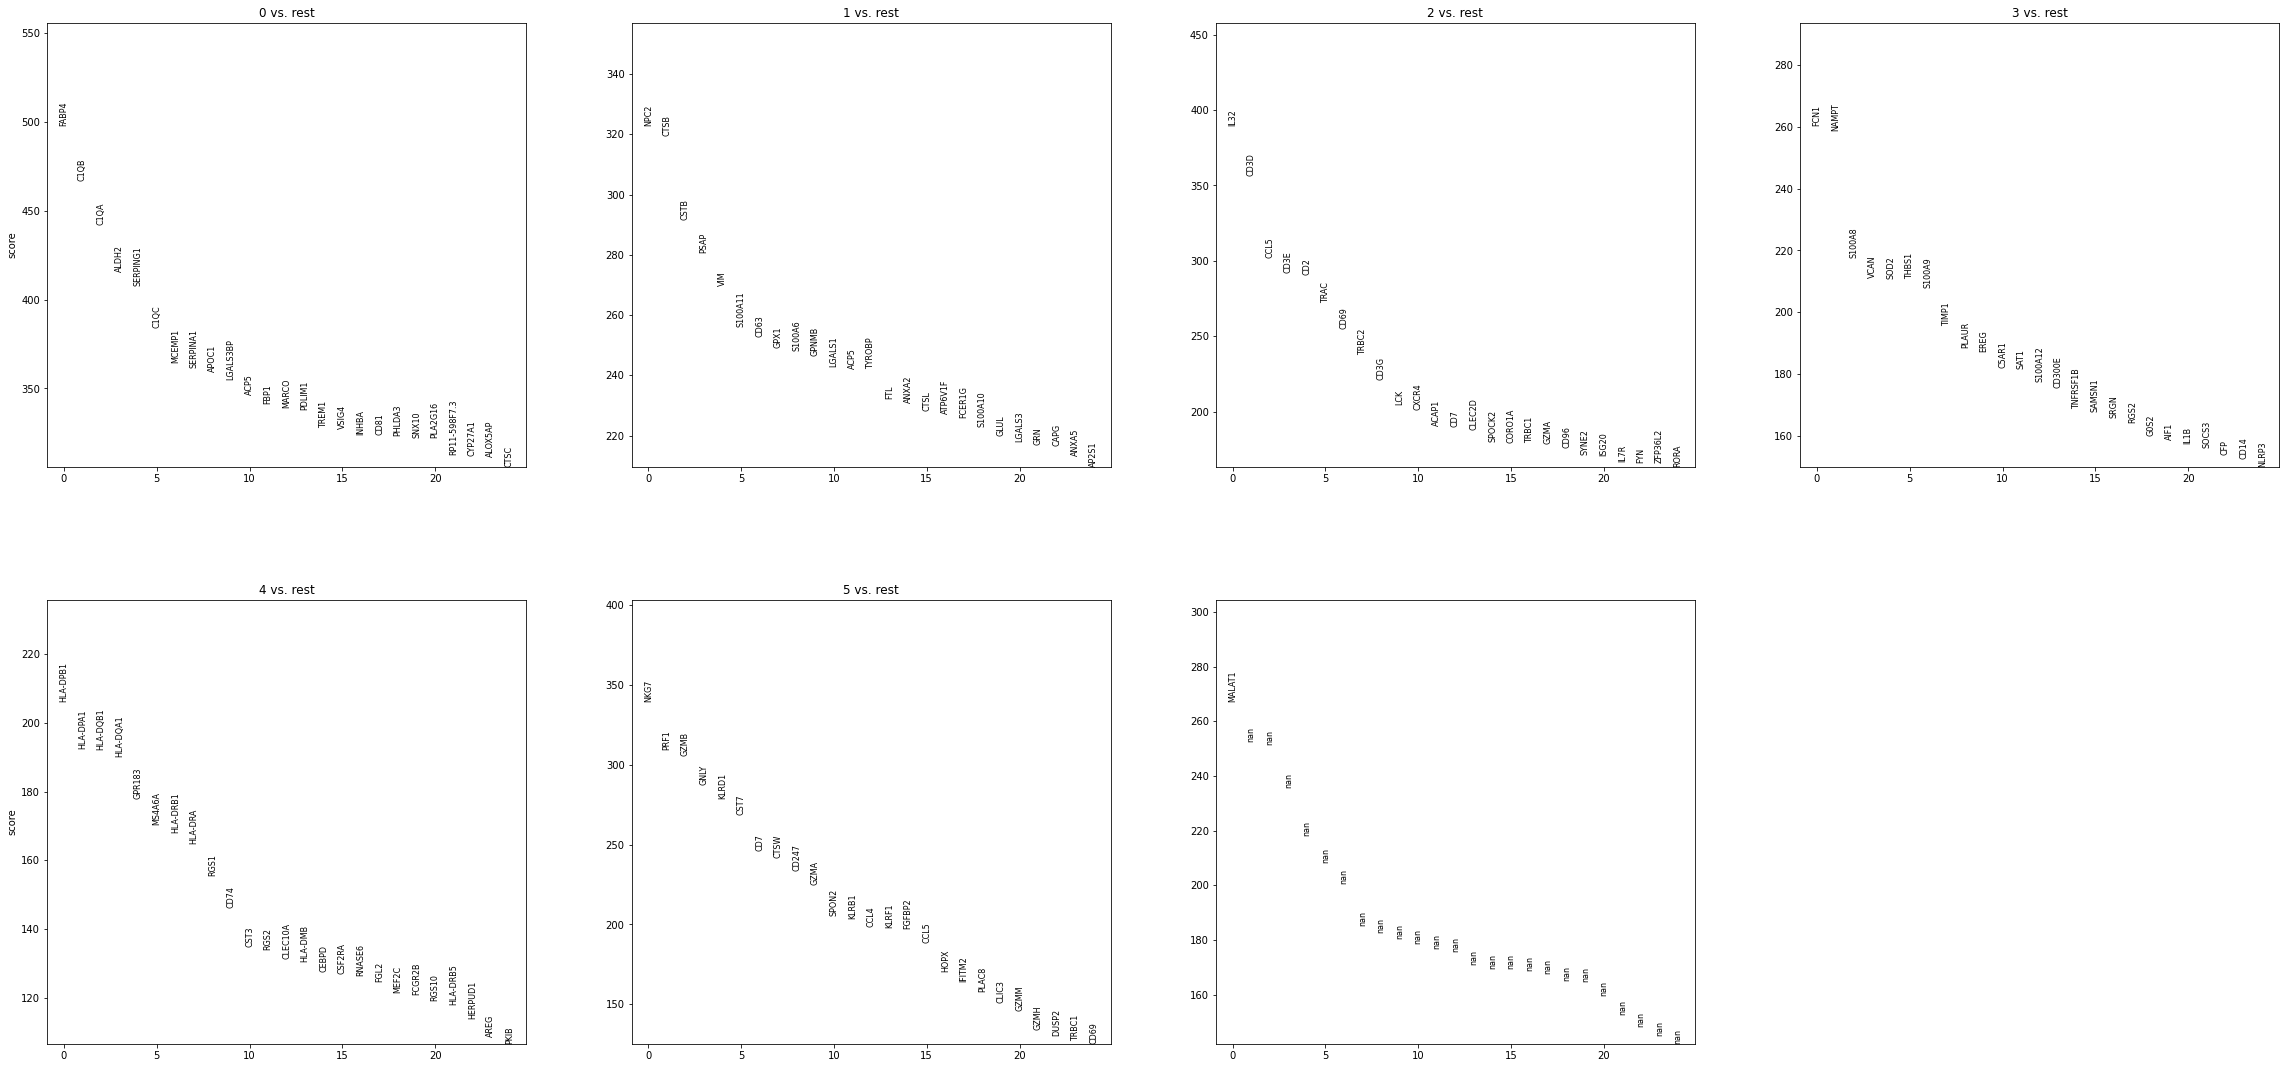

In [127]:
sc.tl.rank_genes_groups(subset_immune, 'leiden_sub', method='t-test', key_added = "t-test", use_raw=True)
sc.pl.rank_genes_groups(subset_immune, n_genes=25, sharey=False, key = "t-test", gene_symbols = "gene_symbols-0")

In [1]:
subset_immune

NameError: name 'subset_immune' is not defined

In [ ]:
sc.tl.filter_rank_genes_groups(subset_immune, min_fold_change=3, key="t-test", use_raw=True)

Filtering genes using: min_in_group_fraction: 0.25 min_fold_change: 3, max_out_group_fraction: 0.5


In [ ]:
subset_immune.uns["rank_genes_groups_filtered"]

In [ ]:
# visualize results
sc.pl.rank_genes_groups(subset_immune, key='rank_genes_groups_filtered')

In [ ]:
sc.get.rank_genes_groups_df(subset_immune, key='rank_genes_groups_filtered')

In [ ]:
# visualize results using dotplot
sc.pl.rank_genes_groups_dotplot(subset_immune, n_genes=5, key='rank_genes_groups_filtered',  gene_symbols = "gene_symbols-0")

In [59]:
sc.logging.print_versions()


-----
anndata     0.7.5
scanpy      1.8.2
sinfo       0.3.1
-----
PIL                 8.1.0
anndata             0.7.5
anyio               NA
attr                20.3.0
babel               2.9.0
backcall            0.2.0
brotli              1.0.9
certifi             2020.12.05
cffi                1.14.4
chardet             4.0.0
cloudpickle         1.6.0
constants           NA
cycler              0.10.0
cython_runtime      NA
dask                2020.12.0
dateutil            2.8.1
decorator           4.4.2
future_fstrings     NA
google              NA
h5py                2.10.0
highs_wrapper       NA
idna                2.10
igraph              0.8.3
ipykernel           5.4.3
ipython_genutils    0.2.0
ipywidgets          7.6.3
jedi                0.18.0
jinja2              2.11.2
joblib              1.0.0
json5               NA
jsonschema          3.2.0
jupyter_server      1.2.1
jupyterlab_server   2.1.2
kiwisolver          1.3.1
leidenalg           0.8.3
llvmlite            0.35.0
louv